# Текущий контроль 9 (реализация): нейронная сеть на PyTorch

В исходном файле разобраны нейрон, слой, функции активации и потерь, а затем показано обучение сети с ручным обратным распространением ошибки. Отдельной формулировки финального задания в файле нет. Здесь эти примеры собраны в **последовательную, запускаемую учебную работу**: от одного умножения до двухслойной сети, которая приближает нелинейную функцию.

Внешние CSV и рисунки не нужны: данные создаются в коде, графики строятся заново. Все случайные величины фиксируются одним seed, чтобы результаты можно было повторить.

**Что получится:** мы вручную напишем прямой и обратный проход, проверим производные с помощью `torch.autograd`, обучим нейрон стохастическим градиентным спуском и сравним линейную модель с сетью для задачи $y\approx x^2$.

## 1. Тензоры, формы и обозначения

В PyTorch данные представлены тензорами. Форма тензора показывает, сколько элементов находится вдоль каждой оси. Для партии из $N$ объектов с $d$ признаками:

| Обозначение | Форма | Смысл |
|---|---|---|
| $X$ | $(N,d)$ | строки — объекты, столбцы — признаки |
| $W$ | $(d,m)$ | веса $m$ нейронов |
| $b$ | $(m,)$ | свободные коэффициенты нейронов |
| $Z=XW+b$ | $(N,m)$ | ответы слоя до активации |

Операция `@` — матричное умножение. Каждый элемент $Z_{ij}$ равен $\sum_{k=1}^{d}X_{ik}W_{kj}+b_j$. PyTorch автоматически добавляет вектор $b$ к каждой строке результата: это **broadcasting**. Проверка форм важна: многие ошибки в нейросетях вызваны неожиданным расширением размерностей.

In [1]:
import math

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from IPython.display import display

SEED = 42
torch.manual_seed(SEED)
# На небольших учебных матрицах один поток уменьшает накладные расходы CPU.
torch.set_num_threads(1)
plt.style.use('seaborn-v0_8-whitegrid')
print(f'PyTorch: {torch.__version__}; устройство: CPU')

PyTorch: 2.14.1+cpu; устройство: CPU


## 2. Один нейрон и слой нейронов

Один нейрон вычисляет $z=\mathbf{x}^{T}\mathbf{w}+b$. Пока нет функции активации, это просто линейная комбинация входных признаков. Значения из исходного примера дают $z=4{,}8$:

$$1\cdot0{,}2+2\cdot0{,}8+3\cdot(-0{,}5)+2{,}5\cdot1+2=4{,}8.$$

Слой объединяет несколько нейронов: каждый столбец матрицы весов отвечает за один выход. Для трёх входных объектов матричное умножение выполняет все вычисления сразу.

In [2]:
example = torch.tensor([1.0, 2.0, 3.0, 2.5])
weights = torch.tensor([0.2, 0.8, -0.5, 1.0])
bias = 2.0
single_output = torch.dot(example, weights) + bias
print('Ответ одного нейрона:', single_output.item())
assert torch.isclose(single_output, torch.tensor(4.8))

batch = torch.tensor([
    [1.0, 2.0, 3.0, 2.5],
    [2.0, 5.0, -1.0, 2.0],
    [-1.5, 2.7, 3.3, -0.8],
])
layer_weights = torch.tensor([
    [0.2, 0.5, -0.26],
    [0.8, -0.91, -0.27],
    [-0.5, 0.26, 0.17],
    [1.0, -0.5, 0.87],
])
layer_biases = torch.tensor([2.0, 3.0, 0.5])
layer_output = batch @ layer_weights + layer_biases
print(f'Формы: X={tuple(batch.shape)}, W={tuple(layer_weights.shape)}, '
      f'b={tuple(layer_biases.shape)}, Z={tuple(layer_output.shape)}')
display(layer_output)

Ответ одного нейрона: 4.800000190734863
Формы: X=(3, 4), W=(4, 3), b=(3,), Z=(3, 3)


tensor([[ 4.8000,  1.2100,  2.3850],
        [ 8.9000, -1.8100,  0.2000],
        [ 1.4100,  1.0510,  0.0260]])

## 3. Зачем нужны функции активации

Если подряд поставить только линейные слои, результат снова будет линейным: $(XW_1+b_1)W_2+b_2=X(W_1W_2)+(b_1W_2+b_2)$. Следовательно, несколько таких слоёв не смогут описать параболу. Нелинейность добавляет **ReLU**:

$$\operatorname{ReLU}(z)=\max(0,z),\qquad
\operatorname{ReLU}'(z)=\begin{cases}1,&z>0,\\0,&z<0.\end{cases}$$

В точке $z=0$ производная не единственна; в нашей ручной реализации выбираем 0. Для многоклассовой классификации часто используют **softmax**: $p_k=e^{z_k}/\sum_je^{z_j}$. Его выходы неотрицательны и суммируются в 1. Здесь softmax показан как отдельный учебный пример: дальнейшая задача $y\approx x^2$ является **регрессией**, поэтому её выходной слой оставляем линейным.

In [3]:
relu_values = torch.relu(torch.tensor([-2.0, 0.0, 3.0]))
logits = torch.tensor([[2.0, 1.0, -1.0], [0.1, 0.2, 1.4]])
probabilities = torch.softmax(logits, dim=1)
labels = torch.tensor([0, 2])

# Кросс-энтропия для правильного класса: -log(p_правильного).
manual_ce = -torch.log(probabilities[torch.arange(len(labels)), labels]).mean()
# Готовая функция получает логиты, сама применяет устойчивый log-softmax.
builtin_ce = F.cross_entropy(logits, labels)

print('ReLU([-2, 0, 3]) =', relu_values.tolist())
print('Вероятности softmax:')
display(probabilities)
print('Суммы по строкам:', probabilities.sum(dim=1).tolist())
print(f'Кросс-энтропия вручную: {manual_ce.item():.6f}; '
      f'F.cross_entropy: {builtin_ce.item():.6f}')
assert torch.allclose(manual_ce, builtin_ce)

ReLU([-2, 0, 3]) = [0.0, 0.0, 3.0]
Вероятности softmax:


tensor([[0.7054, 0.2595, 0.0351],
        [0.1732, 0.1914, 0.6354]])

Суммы по строкам: [1.0000001192092896, 1.0]
Кросс-энтропия вручную: 0.401229; F.cross_entropy: 0.401229


## 4. Функция потерь для регрессии

Модель должна не просто выдавать число, но и получать сигнал о том, насколько прогноз далёк от правильного ответа. Для непрерывного $y$ используем среднеквадратичную ошибку:

$$L(\hat{Y},Y)=\frac{1}{N m}\sum_{i=1}^{N}\sum_{j=1}^{m}(\hat y_{ij}-y_{ij})^2.$$

Здесь $m$ — число выходов на объект; в наших задачах $m=1$. Чем меньше MSE, тем ближе предсказания к целям. Производная по каждому элементу прогноза:

$$\frac{\partial L}{\partial\hat y_{ij}}=\frac{2(\hat y_{ij}-y_{ij})}{Nm}.$$

Эта производная — первый сигнал для обратного прохода. Для классификации с softmax используют кросс-энтропию из предыдущей ячейки, а не MSE.

In [4]:
toy_prediction = torch.tensor([[1.0], [2.0], [4.0]])
toy_target = torch.tensor([[2.0], [2.0], [3.0]])
toy_mse = torch.mean((toy_prediction - toy_target) ** 2)
toy_gradient = 2 * (toy_prediction - toy_target) / toy_prediction.numel()
print(f'MSE = {toy_mse.item():.6f}')
print('Градиент MSE по прогнозу:', toy_gradient.flatten().tolist())

MSE = 0.666667
Градиент MSE по прогнозу: [-0.6666666865348816, 0.0, 0.6666666865348816]


### Один шаг обучения вручную на числах

Чтобы увидеть смысл градиента без матриц, рассмотрим один вход $x=2$, один вес $w=0{,}5$, смещение $b=0$ и правильный ответ $y=3$. Прогноз $\hat y=wx+b=1$, ошибка $L=(1-3)^2=4$. По правилу цепочки:

$$\frac{\partial L}{\partial w}=2(\hat y-y)x=-8,\qquad
\frac{\partial L}{\partial b}=2(\hat y-y)=-4.$$

При скорости обучения $\eta=0{,}1$ новые параметры: $w'=0{,}5-0{,}1(-8)=1{,}3$ и $b'=0-0{,}1(-4)=0{,}4$. Новый прогноз $2\cdot1{,}3+0{,}4=3$ в этом простом примере точно совпадает с целью. В реальной сети таких параметров больше, но принцип обновления тот же.

In [5]:
x_scalar, target_scalar = 2.0, 3.0
weight_scalar, bias_scalar, rate_scalar = 0.5, 0.0, 0.1
before = weight_scalar * x_scalar + bias_scalar
dw = 2 * (before - target_scalar) * x_scalar
db = 2 * (before - target_scalar)
weight_scalar -= rate_scalar * dw
bias_scalar -= rate_scalar * db
after = weight_scalar * x_scalar + bias_scalar
print(f'До шага: прогноз={before:.1f}, MSE={(before-target_scalar)**2:.1f}')
print(f'Градиенты: dL/dw={dw:.1f}, dL/db={db:.1f}')
print(f'После шага: w={weight_scalar:.1f}, b={bias_scalar:.1f}, '
      f'прогноз={after:.1f}, MSE={(after-target_scalar)**2:.1f}')

До шага: прогноз=1.0, MSE=4.0
Градиенты: dL/dw=-8.0, dL/db=-4.0
После шага: w=1.3, b=0.4, прогноз=3.0, MSE=0.0


## 5. Ручной обратный проход: правило цепочки

Для плотного слоя $Z=XW+b$ пусть $G_Z=\partial L/\partial Z$ — градиент, пришедший от следующего этапа. Тогда:

$$\frac{\partial L}{\partial W}=X^TG_Z,\qquad
\frac{\partial L}{\partial b}=\sum_{i=1}^{N}(G_Z)_{i,:},\qquad
\frac{\partial L}{\partial X}=G_ZW^T.$$

Последняя формула передаёт градиент **предыдущему** слою. Для ReLU градиент пропускается только там, где вход был положительным:

$$G_X=G_Z\odot\mathbf{1}_{X>0}.$$

Знак $\odot$ означает поэлементное умножение. Класс `Dense` сохраняет вход последнего прямого прохода, потому что он понадобится для $X^TG_Z$. `ReLU` аналогично сохраняет маску. Важно: это **ручная реализация** производных на тензорах PyTorch; `autograd` в обучении ниже не используется.

In [6]:
class Dense:
    # W: (число входов, число нейронов); b: (число нейронов,).
    def __init__(self, n_inputs, n_neurons):
        self.weights = torch.randn(n_inputs, n_neurons) * math.sqrt(2 / n_inputs)
        self.biases = torch.zeros(n_neurons)

    def forward(self, inputs):
        self.inputs = inputs
        return inputs @ self.weights + self.biases

    def backward(self, dvalues):
        # Сначала вычисляем все градиенты; параметры изменим позже.
        self.dweights = self.inputs.T @ dvalues
        self.dbiases = dvalues.sum(dim=0)
        return dvalues @ self.weights.T


class ReLU:
    def forward(self, inputs):
        self.positive_mask = inputs > 0
        return torch.clamp(inputs, min=0)

    def backward(self, dvalues):
        return dvalues * self.positive_mask


class MSELoss:
    def forward(self, predictions, targets):
        if predictions.shape != targets.shape:
            raise ValueError('Формы прогноза и цели должны совпадать.')
        return torch.mean((predictions - targets) ** 2)

    def backward(self, predictions, targets):
        return 2 * (predictions - targets) / predictions.numel()

## 6. Проверка ручных производных через autograd

Ошибку в формулах градиента трудно заметить по одному графику обучения. Поэтому проведём независимую проверку: возьмём те же начальные веса, вычислим градиенты вручную и через механизм автоматического дифференцирования PyTorch. Сравнение делаем **до изменения параметров**.

Для сети с одним скрытым слоем:

$$Z_1=XW_1+b_1,\quad A_1=\operatorname{ReLU}(Z_1),\quad
\hat Y=A_1W_2+b_2.$$

Обратный путь идёт в противоположном порядке: MSE $\rightarrow$ второй Dense $\rightarrow$ ReLU $\rightarrow$ первый Dense. Если максимальная разница производных близка к нулю, реализация согласуется с autograd.

In [7]:
torch.manual_seed(SEED)
check_x = torch.tensor([[-0.7], [0.2], [0.9]])
check_y = check_x.square()
check_fc1, check_relu, check_fc2 = Dense(1, 4), ReLU(), Dense(4, 1)
criterion = MSELoss()

# Ручной прямой и обратный проход.
check_hidden = check_relu.forward(check_fc1.forward(check_x))
check_prediction = check_fc2.forward(check_hidden)
manual_gradient = criterion.backward(check_prediction, check_y)
manual_gradient = check_fc2.backward(manual_gradient)
manual_gradient = check_relu.backward(manual_gradient)
check_fc1.backward(manual_gradient)

# Независимый граф autograd с копиями тех же параметров.
w1 = check_fc1.weights.clone().detach().requires_grad_(True)
b1 = check_fc1.biases.clone().detach().requires_grad_(True)
w2 = check_fc2.weights.clone().detach().requires_grad_(True)
b2 = check_fc2.biases.clone().detach().requires_grad_(True)
auto_prediction = torch.relu(check_x @ w1 + b1) @ w2 + b2
F.mse_loss(auto_prediction, check_y).backward()

gradient_differences = {
    'W1': (check_fc1.dweights - w1.grad).abs().max().item(),
    'b1': (check_fc1.dbiases - b1.grad).abs().max().item(),
    'W2': (check_fc2.dweights - w2.grad).abs().max().item(),
    'b2': (check_fc2.dbiases - b2.grad).abs().max().item(),
}
print('Максимальные абсолютные разницы градиентов:', gradient_differences)
assert max(gradient_differences.values()) < 1e-6

Максимальные абсолютные разницы градиентов: {'W1': 0.0, 'b1': 0.0, 'W2': 0.0, 'b2': 0.0}


## 7. Как веса меняются при обучении

Градиент указывает направление **роста** функции потерь, поэтому для её уменьшения параметры обновляются в противоположную сторону:

$$W\leftarrow W-\eta\frac{\partial L}{\partial W},\qquad
b\leftarrow b-\eta\frac{\partial L}{\partial b},$$

где $\eta$ — скорость обучения. Если использовать всю обучающую выборку для одного обновления, это **полный (batch) градиентный спуск**. Если после каждого отдельного объекта — **стохастический SGD**. Партии промежуточного размера дают **mini-batch SGD**. Один *epoch* означает проход по всем обучающим объектам; число обновлений за эпоху зависит от размера партии.

Ниже одна функция поддерживает все три режима. Градиенты вычисляются по партии, а потом обновляются все слои. Перемешивание выполняется только для обучения; проверочная часть не участвует в обновлении весов.

In [8]:
def forward_network(layers, inputs):
    output = inputs
    for layer in layers:
        output = layer.forward(output)
    return output


def train_network(layers, x_train, y_train, x_valid, y_valid,
                  *, epochs, learning_rate, batch_size, seed=SEED):
    criterion = MSELoss()
    generator = torch.Generator().manual_seed(seed)
    history = {'train_mse': [], 'valid_mse': []}

    for _ in range(epochs):
        order = torch.randperm(len(x_train), generator=generator)
        for indices in order.split(batch_size):
            batch_x, batch_y = x_train[indices], y_train[indices]

            # 1) Прямой проход и значение ошибки для текущей партии.
            predictions = forward_network(layers, batch_x)
            criterion.forward(predictions, batch_y)

            # 2) Обратный проход: начиная с производной MSE.
            gradient = criterion.backward(predictions, batch_y)
            for layer in reversed(layers):
                gradient = layer.backward(gradient)

            # 3) Все градиенты уже посчитаны; теперь обновляем параметры.
            with torch.no_grad():
                for layer in layers:
                    if isinstance(layer, Dense):
                        layer.weights -= learning_rate * layer.dweights
                        layer.biases -= learning_rate * layer.dbiases

        with torch.no_grad():
            train_pred = forward_network(layers, x_train)
            valid_pred = forward_network(layers, x_valid)
            history['train_mse'].append(criterion.forward(train_pred, y_train).item())
            history['valid_mse'].append(criterion.forward(valid_pred, y_valid).item())

    return history

## 8. Один нейрон учится линейной зависимости методом SGD

Создадим данные с известными коэффициентами:

$$y=2x_1-x_2+0{,}5x_3+3x_4+0{,}7+\varepsilon,$$

где $\varepsilon$ — небольшая случайная помеха. Так можно не только смотреть на MSE, но и сравнить выученные веса с настоящими. Для каждого объекта делаем отдельное обновление (`batch_size=1`), как в разделе SGD исходного примера. Данные для проверки отделяем заранее; сеть их не использует при обучении.

In [9]:
torch.manual_seed(SEED)
linear_x = torch.randn(240, 4)
true_weights = torch.tensor([[2.0], [-1.0], [0.5], [3.0]])
true_bias = 0.7
linear_y = linear_x @ true_weights + true_bias + 0.05 * torch.randn(240, 1)

generator = torch.Generator().manual_seed(SEED)
order = torch.randperm(len(linear_x), generator=generator)
train_indices, valid_indices = order[:180], order[180:]
linear_train_x, linear_train_y = linear_x[train_indices], linear_y[train_indices]
linear_valid_x, linear_valid_y = linear_x[valid_indices], linear_y[valid_indices]

linear_neuron = Dense(4, 1)
linear_history = train_network(
    [linear_neuron], linear_train_x, linear_train_y,
    linear_valid_x, linear_valid_y,
    epochs=60, learning_rate=0.01, batch_size=1,
)
print(f'SGD: train MSE={linear_history["train_mse"][-1]:.5f}; '
      f'validation MSE={linear_history["valid_mse"][-1]:.5f}')
print('Настоящие веса:', true_weights.flatten().tolist(), 'bias:', true_bias)
print('Найденные веса:', linear_neuron.weights.flatten().tolist(),
      'bias:', linear_neuron.biases.item())

SGD: train MSE=0.00266; validation MSE=0.00218
Настоящие веса: [2.0, -1.0, 0.5, 3.0] bias: 0.7
Найденные веса: [2.00226092338562, -0.9985138773918152, 0.5006009340286255, 2.9996426105499268] bias: 0.703874945640564


## 9. Почему для параболы нужен скрытый слой

Теперь построим данные $y=x^2+\varepsilon$ на отрезке $[-1,1]$. Одного линейного нейрона недостаточно: его ответ имеет вид $wx+b$, то есть он может построить только прямую. Сеть `Dense(1, 16) → ReLU → Dense(16, 1)` задаёт кусочно-линейную функцию; при достаточном числе нейронов такие отрезки приближают параболу.

Сравним обе модели **на одной и той же отложенной части**. Модели учатся только по train; validation служит для проверки обобщения. Здесь используем полный градиентный спуск (`batch_size=len(train)`), чтобы графики потерь было проще читать. Число эпох у моделей различается: это демонстрация выразительности, а не сравнение времени алгоритмов.

In [10]:
torch.manual_seed(SEED)
curve_x = torch.linspace(-1.0, 1.0, 160).reshape(-1, 1)
curve_y = curve_x.square() + 0.05 * torch.randn_like(curve_x)
order = torch.randperm(len(curve_x), generator=torch.Generator().manual_seed(SEED))
curve_train_x, curve_train_y = curve_x[order[:120]], curve_y[order[:120]]
curve_valid_x, curve_valid_y = curve_x[order[120:]], curve_y[order[120:]]

torch.manual_seed(SEED)
straight_model = [Dense(1, 1)]
straight_history = train_network(
    straight_model, curve_train_x, curve_train_y, curve_valid_x, curve_valid_y,
    epochs=400, learning_rate=0.05, batch_size=len(curve_train_x),
)

torch.manual_seed(SEED)
neural_network = [Dense(1, 16), ReLU(), Dense(16, 1)]
network_history = train_network(
    neural_network, curve_train_x, curve_train_y, curve_valid_x, curve_valid_y,
    epochs=2500, learning_rate=0.05, batch_size=len(curve_train_x),
)

print(f'Линейный нейрон: train MSE={straight_history["train_mse"][-1]:.5f}, '
      f'validation MSE={straight_history["valid_mse"][-1]:.5f}')
print(f'Сеть с ReLU:    train MSE={network_history["train_mse"][-1]:.5f}, '
      f'validation MSE={network_history["valid_mse"][-1]:.5f}')

Линейный нейрон: train MSE=0.09600, validation MSE=0.09107
Сеть с ReLU:    train MSE=0.00404, validation MSE=0.00529


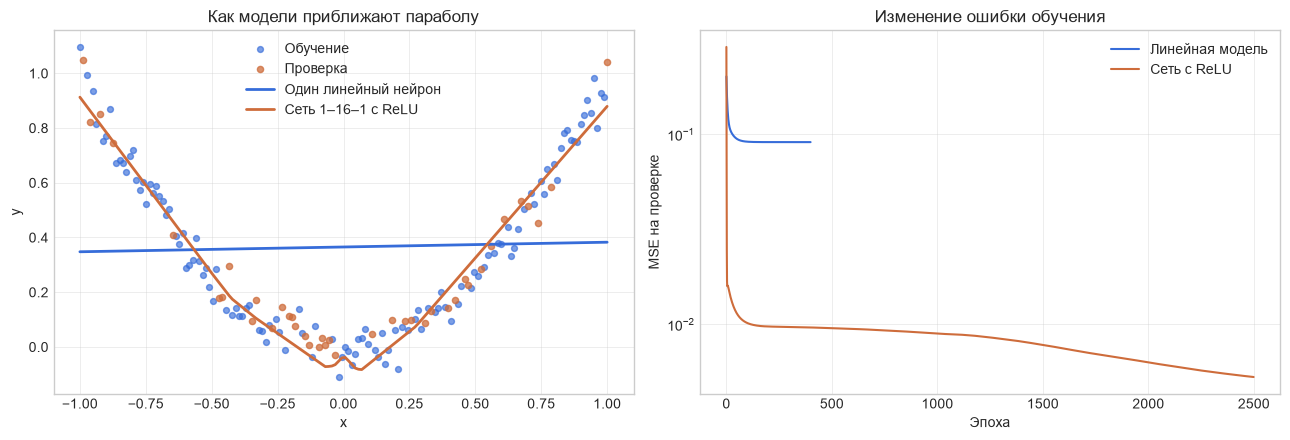

In [11]:
with torch.no_grad():
    straight_prediction = forward_network(straight_model, curve_x).flatten().numpy()
    network_prediction = forward_network(neural_network, curve_x).flatten().numpy()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(curve_train_x.flatten().numpy(), curve_train_y.flatten().numpy(),
                s=18, alpha=0.65, label='Обучение')
axes[0].scatter(curve_valid_x.flatten().numpy(), curve_valid_y.flatten().numpy(),
                s=20, alpha=0.75, label='Проверка')
axes[0].plot(curve_x.flatten().numpy(), straight_prediction,
             label='Один линейный нейрон', lw=2)
axes[0].plot(curve_x.flatten().numpy(), network_prediction,
             label='Сеть 1–16–1 с ReLU', lw=2)
axes[0].set(xlabel='x', ylabel='y', title='Как модели приближают параболу')
axes[0].legend()

axes[1].plot(straight_history['valid_mse'], label='Линейная модель')
axes[1].plot(network_history['valid_mse'], label='Сеть с ReLU')
axes[1].set(xlabel='Эпоха', ylabel='MSE на проверке',
            title='Изменение ошибки обучения')
axes[1].set_yscale('log')
axes[1].legend()
fig.tight_layout()
plt.show()

## 10. Что важно понять по результату

1. **Нейрон** считает взвешенную сумму входов и смещение; **слой** делает это сразу для нескольких нейронов и объектов.
2. **ReLU** добавляет нелинейность. Без неё сколько бы линейных слоёв мы ни поставили, сеть останется одной линейной моделью.
3. **Функция потерь** превращает ошибку прогноза в число. Для регрессии здесь используется MSE; для многоклассовой классификации показана кросс-энтропия с softmax.
4. **Обратное распространение** — применение правила цепочки от выхода к входу. Плотный слой вычисляет производные по весам, смещениям и входам; ReLU блокирует градиент для неположительных входов.
5. **Градиентный спуск** обновляет параметры в сторону уменьшения ошибки. При размере партии 1 это SGD; при партии размером со весь train — полный градиентный спуск.
6. Проверка через **autograd** показала нулевую максимальную разницу для всех четырёх групп градиентов. На линейных данных SGD нашёл веса примерно $(2{,}002,-0{,}999,0{,}501,3{,}000)$ при истинных $(2,-1,0{,}5,3)$; MSE на отложенных данных составила **0,00218**.
7. На параболе MSE линейного нейрона на отложенных данных составила **0,09107**, сети с ReLU — **0,00529**. Следовательно, скрытый нелинейный слой действительно позволил приблизить форму зависимости. Подробная интерпретация есть в README.